## The Core Value Object & Derivatives
$\frac{df}{da}$ = how does (slightly) change in a affects f

NN are just mathmaticall expressions. they take the input data and weights of the NN as input as a mathematical expression and the output are the predections of the neural net (or the loss function)

backpropogation is something really general (a mathmatical tool). 

In [258]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline 

### A simple example derivative

In [259]:
def f(x):
    return 3*x**2 - 4*x +5

[-5.   -4.75 -4.5  -4.25 -4.   -3.75 -3.5  -3.25 -3.   -2.75 -2.5  -2.25
 -2.   -1.75 -1.5  -1.25 -1.   -0.75 -0.5  -0.25  0.    0.25  0.5   0.75
  1.    1.25  1.5   1.75  2.    2.25  2.5   2.75  3.    3.25  3.5   3.75
  4.    4.25  4.5   4.75]


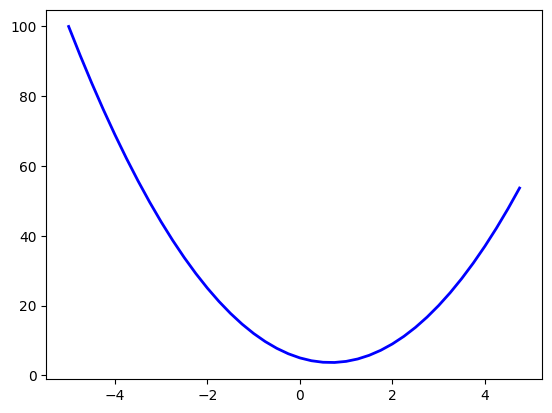

In [260]:
f(3.0)

xs = np.arange(-5,5,0.25)
print(xs)

ys = f(xs)
ys

plt.plot(xs,ys, color='blue', linewidth=2, label='f(x)')

What is the derivative of this function f(x) at any single point x ? 

We are NOT going to use the derivative expression we learned in high school. 
instead we will use: 

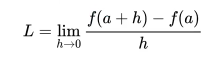

if we slightlly increase samll number h how does the function respond ? with what sensitivity does it respond ? what is the slope of that point ? 

**slope = the function responding** (does the function go up or down ? how much ? )

Another good view on derivative: $\frac{df}{da}$ is the ratio between a little change in f to a little change in a. 

If the ratio is positive then when a is bigger f changing in the sanme direction. 

Notation note: 
1. da is h(which is tiny step in x axis)
2. df is  f(a+h)-f(a) (the tiny change in the result f)

In [261]:
h=0.001
x=3.0
f(x+h) # looking at the graph of the function we expect the f(x+h) > f(x) since the function is increasing at x=3.0

20.014003000000002

In [262]:
# The slope is: 
(f(x+h)-f(x))/h # to get the real value, h neeeds to very samll (h->0).the slope is negative. where x+h-x = h

14.00300000000243

In [263]:
#lets get more complex
a=2.0
b=-3.0
c=10.0
d=a*b+c
print(d)

4.0


In [264]:
h = 0.0001


#inputs
a=2.0
b=-3.0
c=10.0

d1 = a*b + c
a +=h
d2 = a*b + c #d1 is bumped by a

print("d1", d1)
print('d2',d2)
print('slope', (d2-d1)/h) # that's the slope of the function d(a) = a*b + c at a=2.0
# d2-d1 is how much the function increasd when we bumped the input we intrested in by tiny amount and this is normilized by h(to get the slope) 
#increasing a is making d2 smaller
# this is df/da 

d1 4.0
d2 3.999699999999999
slope -3.000000000010772


Now we would like a data structures to maintain the big expresions of the NN

In [265]:
class Value:

    def __init__(self,data):
        self.data = data

    '''the __repr__ function helps us to see the value of the object when we print it out. 
    without it, we will see the memory address of the object.'''

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data) # new object is created
        return out

    def __mul__(self, other):
            out = Value(self.data * other.data) # new object is created
            return out

a = Value(2.0)
b = Value(-3.0)
c = Value(10.0)
a + b # same as a.__add__(b)
a*b # same as a.__mul__(b)
a*b + c # same as a.__mul__(b).__add__(c)


Value(data=4.0)

Now, we want the conective tissue of this expression. we would want to keep the expresion graph so we will keep poiners about what values produce what other values. 

Also, we want to know which operation created the value ( for d._prev we got: {Value(data=-6.0), Value(data=10.0)} we know a*b gave: -6+10 = 4, but someone else would'nt know what operation between a*b and c gives 4 ! )

In [266]:
class Value:

    def __init__(self, data, _children=(), _op='', label=''):# why op= '' ? becuse we want to have a default value for the _op parameter. if we don't provide a value for _op, it will be an empty string. 
        self.data = data
        self.grad = 0.0 # at initilazation we assume no impact does not effect on the output. we will update the grad later when we do backpropagation.
        self._prev = set(_children) # is the set of children of the current node. it is a set because we don't want to have duplicates(efficency). 
        self._backward = lambda: None #  at each node we will have a function(by defualt does not do anything - case example for a leaf node) that will compute the gradient of the current node with respect to its children (take inputs and produce output). it will use CHAIN RULE. 
        self._op = _op # we use the _op parameter to store the operation that created the current node.
        self.label = label # this is useful for visualization. we can use the label to store the name of the variable. 


    '''the __repr__ function helps us to see the value of the object when we print it out. 
    without it, we will see the memory address of the object.'''

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other): # self + other
        other = other if isinstance (other, Value) else Value(other) # if other is not a Value object, convert it to a Value object
        out = Value(self.data + other.data, (self, other), '+') # new object is created. (self, other) is the tuple of children of the current node.

        def _backward():
            # for a neuran that has two inputs, we need to claculate the gradient of each node, self(the first input) and other(the second output): 
            self.grad += 1.0 * out.grad # the gradient of the current node with respect to its children is 1.0 because the derivative of x+y with respect to x is 1.0 and with respect to y is also 1.0. we multiply by out.grad because of the chain rule.
            other.grad += 1.0 * out.grad 
        out._backward = _backward

        return out

    def __mul__(self, other):
            other = other if isinstance (other, Value) else Value(other) #isinstance return whether an object is an instance of a class or of a subclass thereof.
            out = Value(self.data * other.data, (self, other), '*') # new object is created

            def _backward():
                self.grad +=  other.data * out.grad # out.grad is the CHAIN RULE
                other.grad += self.data * out.grad
            out._backward = _backward

            return out

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting int/float powers for now"
        out = Value(self.data**other, (self,), f'**{other}')

        def _backward(): # backprpogating through the power function. what is the meaning ? 
            self.grad += other * (self.data ** (other -1)) * out.grad # the local derivative is other *(...) and the CHAIN RULE is out.grad !
        out._backward = _backward

        return out

    def __rmul__(self, other): # this is for the case when we have a scalar on the left side of the multiplication. for example: 2 * a where a is a Value object. in this case, the __mul__ method will not be called because the left operand is not a Value object. instead, the __rmul__ method will be called.
        return self * other

    def __radd__(self, other):
        return self + other

    def __truediv__(self, other): # self / other
        return self * other**-1

    def __sub__(self, other):
        return self + (-other)
    
    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1) / (math.exp(2*x) + 1)
        out = Value(t, (self,), 'tanh')
        
        def _backward():
                self.grad += (1 - t**2) * out.grad
        out._backward = _backward

        return out

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self, ), 'exp')

        def _backward():
            self.grad += out.data * out.grad # why multypling ? 
        out._backward = _backward

        return out

    def backward(self):
        # building the topological graph
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev: # go throgh all the children of the not visited node
                    build_topo(child)
                topo.append(v) # after all the children have been procceded then only the current node is added to topo. that way we grantte a node will be in the list only after all its children arein the list. 
        build_topo(self) # for us we start to topo sort from o(the last node). we go from o to all of its children and we need to lay them out from left to right. 

        self.grad = 1.0 

        for node in reversed(topo):
            node._backward()


a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
e = a*b; e.label = 'e'
d = e + c; d.label='d' # the same as a.__mul__(b).__add__(c)
f= Value(-2.0, label='f')
L = d*f; L.label='L'
d


Value(data=4.0)

In [267]:
d._prev # this is the set of children of the current node

{Value(data=-6.0), Value(data=10.0)}

In [268]:
d._op

'+'

becuse the expression will be big, we would like a way to nicely visualize expressions the we're building out. lets look at a copy-paste scary code:

In [269]:
from graphviz import Digraph

def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges
  
def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right
  
  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    # for any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
    if n._op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name = uid + n._op, label = n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)
      
  for n1, n2 in edges:
    # connect n1 to the op node of n2
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    
  return dot

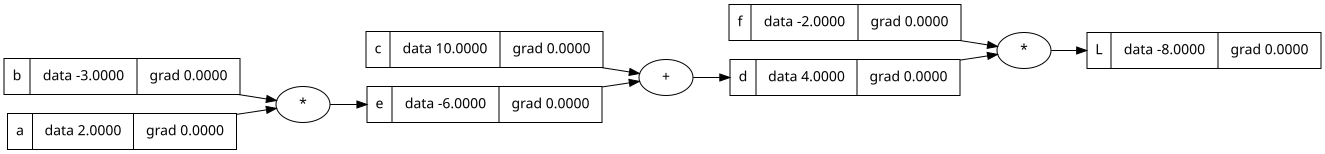

In [270]:
draw_dot(L)

## Manual Backpropagation
Now we will do backprpogation. we are starting at the end ( L ) snd going to reverse and calculate the gradient along all the intermediate values. 

For every single value we calculate the derivative of that node with respect to L ( dL /dL, dL/df, dL/dd etc ). 

In the NN setting we are very intrsetd in the derivative of this loss functio (L) with respect to the weights( here are a,b,c and f) of the NN. we would like to know how this weights are affecting the loss function. we intrestend in the derivative of the output with respect to **some** of it's leaf nodes and the leaf nodes will be the weightes of the NN and the other leaf nodes will be the data itself. we usualy won't want or use the derivative of the L function with respect to input data becuase the data is fixed but the weights will be iterated using gradient information. 

Let's start with the manual calculations:

$\frac{dL}{dL} =1$ # becuase when i change L a little bit by h L changes also by h. 

$$L = d \cdot f$$
$$\rightarrow \frac{dL}{dd} = f$$
$$\rightarrow \frac{dL}{df} = d$$

by definition: $\frac{f(x+h)-f(x)}{h} = ((d + h)\cdot f - \frac{d\cdot f)}{h}) = ... = f$


**NOTE : this is a very important example to understand what's happening when backpropogating through a multipication node**  

In [271]:
f.grad = 4.0 # = d
d.grad = -2.0 # = f

In [272]:
L.grad = 1.0 

We want to see how a specific button(w) influance the system(L)

In [273]:
def lol(): 

    h = 0.0001

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label = 'e'
    d = e + c; d.label='d' # the same as a.__mul__(b).__add__(c)
    f= Value(-2.0, label='f')
    L = d*f; L.label='L'
    L1 = L.data

    a = Value(2.0 + h, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label = 'e'
    d = e + c; d.label='d' # the same as a.__mul__(b).__add__(c)
    f= Value(-2.0 , label='f')
    L = d*f; L.label='L'
    L2 = L.data

    print((L2-L1)/h) # this is how much L changed and then normilized by h to get the slope. this is the slope of L with respect to a at a=2.0 (becuase its a we bummped a littele bit by h). 

lol()



6.000000000021544


In [274]:
# Gradient checking: 

def lol(): 

    h = 0.001

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label = 'e'
    d = e + c; d.label='d' # the same as a.__mul__(b).__add__(c)
    f= Value(-2.0, label='f')
    L = d*f; L.label='L'
    L1 = L.data

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label = 'e'
    d = e + c; d.label='d' # the same as a.__mul__(b).__add__(c)
    d.data += h
    f= Value(-2.0, label='f')
    L = d*f; L.label='L'
    L2 = L.data

    print((L2-L1)/h) 

lol()


-2.000000000000668


$\frac{dL}{dc} = ? $

We know how does d changing it influance's L, but how would we know how when c chnages (which is going throgh d) influance L ? 
We can say we know how c impact on d => and also how d impact on L (chain) => then we can somehow put this information toghether to figure out how c impacts L. 

**THIS IS THE CHAIN RULE**

$\frac{dd}{dc} = ? $
$d = c + e => \frac{dd}{dc} = 1.0 + \frac{de}{dc} = ? = 1.0 + 0 = 1.0 $

also $\frac{de}{dc} = 1.0$

knowing how c and e impacts d, how can put this information toghether to get $\frac{dL}{dc}$ ? the answer is THE CHAIN RULE. 

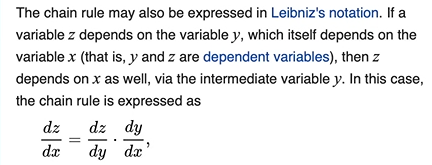

y is the intermidate between z and x. 

In the problem, d is the intermidate between L and c => $\frac{dL}{dc}  = (\frac{dL}{dd}) * (\frac{dd}{dc})$

Multipication is the right way. 

so we KNOW: 
dL / dd = -2.0 
dd / dc = 1.0
=> dL/dc  = -2.0

(this is not right:
L = d * f = (e + c) * f = (a * b + c) * f  
dL /dc = ((a * b + c) * f)/dc = (a * b * f) / dc + f = 0.0 + 1.0 = 1.0)

In [275]:
c.grad = -2.0 
e.grad = -2.0 

In [276]:
# Gradient checking: 

def lol(): 

    h = 0.00001

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label = 'e'
    d = e + c; d.label='d' # the same as a.__mul__(b).__add__(c)
    f= Value(-2.0, label='f')
    L = d*f; L.label='L'
    L1 = L.data

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    c.data += h
    e = a*b; e.label = 'e'
    d = e + c; d.label='d' # the same as a.__mul__(b).__add__(c)
    f= Value(-2.0, label='f')
    L = d*f; L.label='L'
    L2 = L.data

    print((L2-L1)/h) 

lol()


-1.9999999999242843


Continueing to the rest of the graph (before e,c) and applying the chain rule. 

dL/da = (dL/de) * (de/da) # were de/da is the **"local gradient"**

we have dL/de = -2.0 (calculated above)

de/da = da*b/da = b = -3.0 

=> dL/da = 6.0 

becuase of symmetry:

dL/db = -2.0 * (da*b/db ) = -2.0 * a = -4.0 

In [277]:
a.grad = 6 
b.grad = -4.0 

To summraize the manuall back propogation:

we went all the way from L to the leaf nodes, we have done it piece by peice. 
Iterating all the nodes, one by one, and locally applied the CHAIN RULE, we always know what is the derivative of L with respect to this little output and then we look at how this output was produced. this output was produced trough some operation and we have the pointers to the childern node of this operation. 

Now lets see the power of this. we will nudge our inputs to try make L go up.
that's **optimization**

In [278]:
# a.data += 0.01 * a.grad
# b.data += 0.01 * b.grad
# c.data += 0.01 * c.grad
# f.data += 0.01 * f.grad

# e = a * b
# d = e + c
# L = d * f

# print(L.data) # L will go up becuase L is dependent on a,b,c,f and we are updating them in the direction of the gradient.

## manual backpropagation example #2: a neuron
backpropogating through a nueron. 

A bit about a neuron: 
A neuron in physolgy is

A neuron is looking like: 

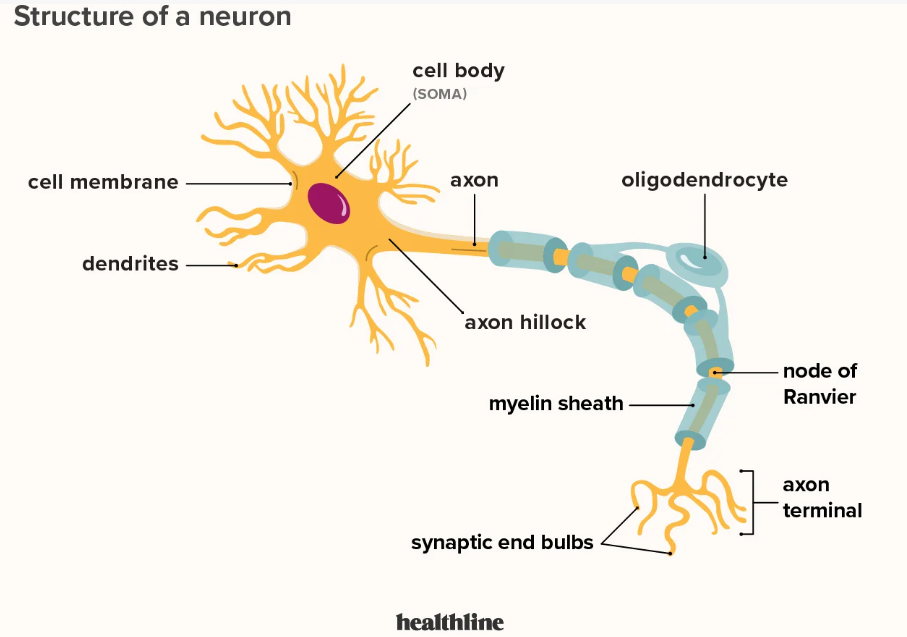

where:
axon is 
synapsa is 

simillarly to this neuron we defain our setting:

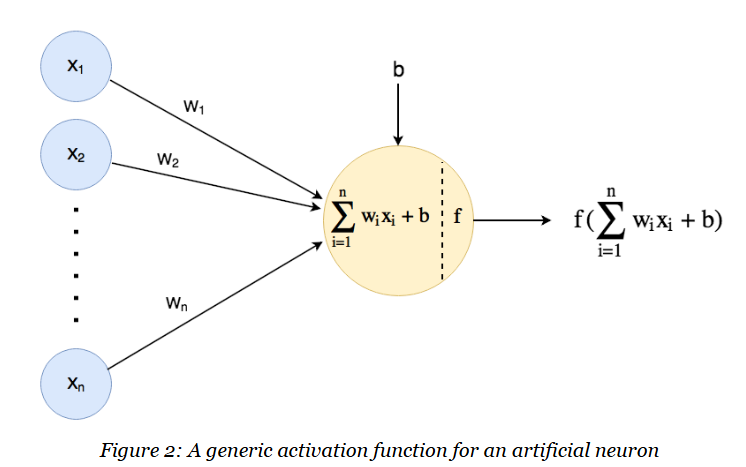

where:
axon is 
synapsa is 

#### tanh function:

Using the tanh function in numpy. 

It can be seein that as inputs (x) come in - they get squashed on the y coordinate.

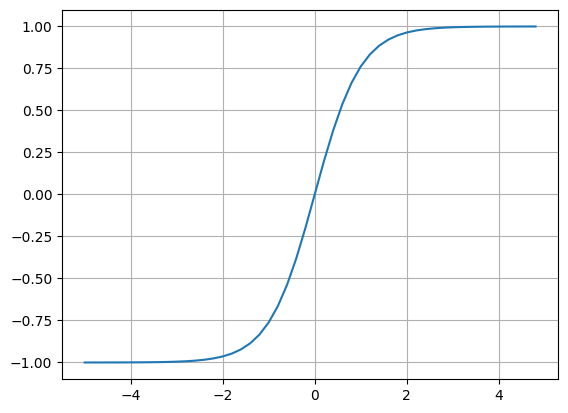

In [279]:
plt.plot(np.arange(-5,5,0.2), np.tanh(np.arange(-5,5,0.2))); plt.grid(); 

Generating two-dimentional nueron:

In [280]:
# inputs x1, x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights w1, w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
b = Value(6.881373587019543, label='b')
# x1w1 + x2w2 + b
x1w1 = x1*w1; x1w1.label='x1*w1'
x2w2 = x2*w2; x2w2.label='x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label='x1*w1 + x2w2'
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh() ; o.label = 'o' # activating tanh on n (which n is the sum of the weighted inputs and bias). 


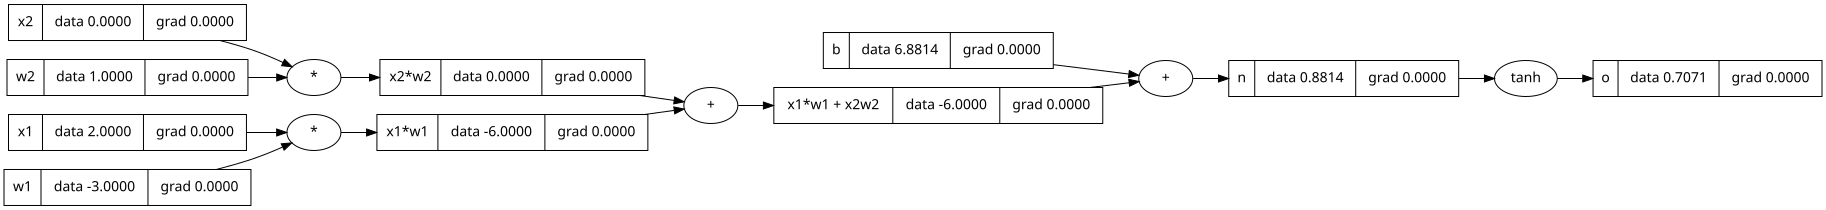

In [281]:
draw_dot(o)

It can be arbitrarily complex function, it does not matter as long as we know how to create the local derivative - how the inputs impact the output - its all we need !

For back propogation we need to ask ourselves, what is the derivative of o with respect to all inputs. 

In an NN we care the most about the neurons with the weights specifically (w1, w2), we are going to change them during optimization. 

In [282]:
o.grad = 1.0 

In [283]:
# o = tanh(n)
# do/dn = dtanh(n))/dn = 1 - tanh(n)**2 = 1 - o**2
1 - o.data**2 # the local derivative of the tanh operation.  

0.4999999999999999

In [284]:
n.grad = 0.5 # = do/dn

In [285]:
x1w1x2w2.grad = 0.5 * 1.0 
b.grad = 0.5 * 1.0

In [286]:
x1w1.grad = 0.5
x2w2.grad = 0.5

In [287]:
# dL/dx2 = dx2w2/dx2 * dL/dx2w2 = w2 * 0.5
x2.grad = w2.data * x2w2.grad
w2.grad = x2.data * x2w2.grad 

In [288]:
x1.grad = w1.data * x1w1.grad
w1.grad = x1.data * x1w1.grad

Based on the results, if we want L (the least neuron output) to increase then:
 - (the neuron) w2 has no gradient so it does not affect L.`
 - (the neuron) w1 should go up (becuase his gradient depending on L is positive => when his value going up so does L) 

###  implementing the backward function for each operation
Now we want to implement this NN but NOT manually. somthing more general. 

In [289]:
o.grad = 1.0 

In [290]:
o._backward() # the output of tanh

In [291]:
n._backward() # looking at the two input nodes of n node and setting their gradients

In [292]:
b._backward() # the defualt -> NONE

In [293]:
x1w1x2w2._backward()

In [294]:
x2w2._backward()
x1w1._backward()

how can we get rid of calling _backwrd() function manually ? 
we've laid out a mathmatical expersion and now we are trying to go backwards through that expression => we never want to call _backward() for any node before we have done everything after it (need n before x1w1 for example). We need to get all of the node dependencies. 

this can be achived by:
#### Topological Sort
In short: a topological sort is a sort that all the edeges only go one way. 

In long: when we are scheduling jobs or tasks, they may have dependencies. For example, before we finish task a, we have to finish b first. In this case, given a set of tasks and their dependencies, how shall we arrange our schedules? There comes an interesting graph algorithm: Topological Sort.

Given a directed acyclic graph (DAG), a topological sort is a linear ordering of all vertices such that for any edge (u, v), u comes before v. Another way to describe it is that when you put all vertices horizontally on a line, all of the edges are pointing from left to right.

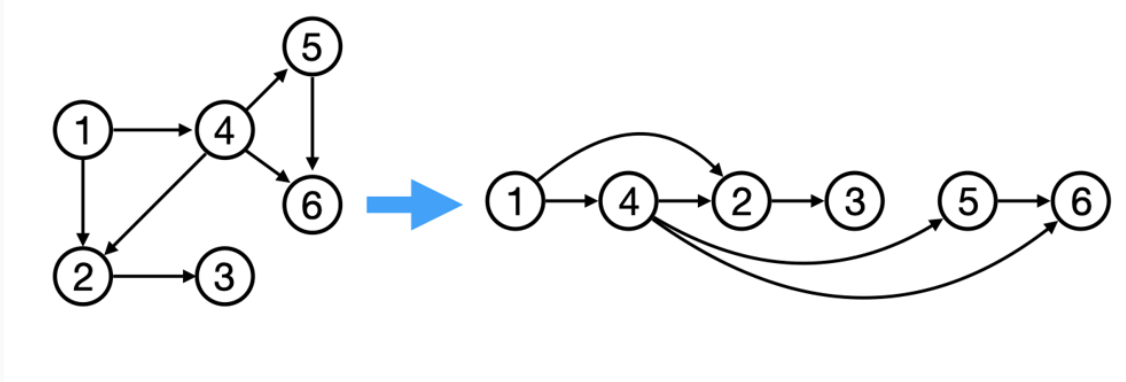

In [295]:
# building the topological graph
topo = []
visited = set()
def build_topo(v):
    if v not in visited:
        visited.add(v)
        for child in v._prev: # go throgh all the children of the not visited node
            build_topo(child)
        topo.append(v) # after all the children have been procceded then only the current node is added to topo. that way we grantte a node will be in the list only after all its children are in the list. 
build_topo(o) # for us we start to topo sort from o(the last node). we go from o to all of its children and we need to lay them out from left to right. 
topo

[Value(data=6.881373587019543),
 Value(data=2.0),
 Value(data=-3.0),
 Value(data=-6.0),
 Value(data=0.0),
 Value(data=1.0),
 Value(data=0.0),
 Value(data=-6.0),
 Value(data=0.8813735870195432),
 Value(data=0.7071067811865476)]

In [ ]:
o.grad = 1.0 

for node in reversed(topo): #starting backpropogating from o
    node._backward()

We want to hide this functinallty and not let code just arround. so we define actual backward in our Value class.

In [297]:
o.backward()

But there is a problem. lets see it:

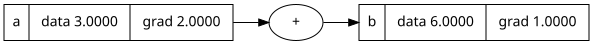

In [298]:
a = Value(3.0,label='a')
b = a + a ; b.label='b'
b.backward()
draw_dot(b)

The gradient of L with respect to a should be: 
$$\frac{db}{da} = \frac{d(a + a)}{da} = 1 + 1 = 2$$
but we got 1. why ? becuase calculating the gradiets we over wrote the previous value (using ony = and not +=). 

how do we solve this ? setting += for all functions 

(self.grad += 1.0 * out.grad, 

other.grad += 1.0 * out.grad

etc)

We would like to implement tanh:

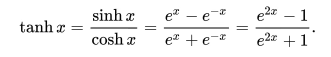

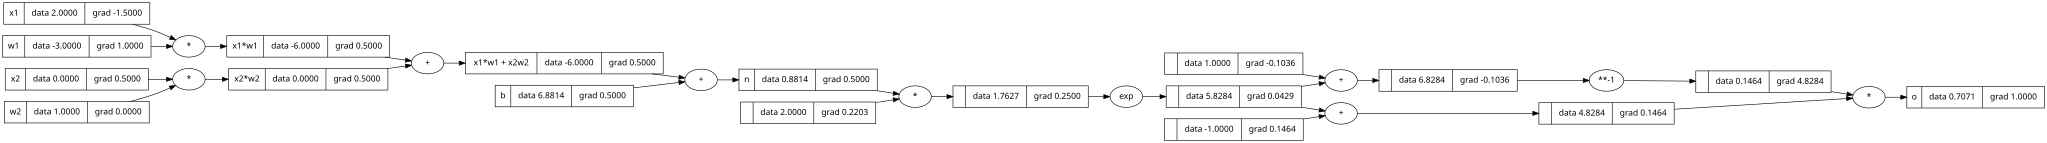

In [299]:
# inputs x1, x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights w1, w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
b = Value(6.881373587019543, label='b')
# x1w1 + x2w2 + b
x1w1 = x1*w1; x1w1.label='x1*w1'
x2w2 = x2*w2; x2w2.label='x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label='x1*w1 + x2w2'
n = x1w1x2w2 + b; n.label = 'n'
# ----
e = (2*n).exp()
o = (e-1) / (e+1)
# ----
o.label = 'o'
o.backward()
draw_dot(o)


need to think of the gradient of the plus, **-1 etc

Using Pytorch to do the same thing:

In [300]:
import torch

In [301]:

x1 = torch.Tensor([2.0]).double()       ; x1.requires_grad = True # with '.requires_grad', this tensor is a variable of interest. From now on, track every mathematical operation it participates in and construct its computational graph behind the scenes.
                                                                  # Later, when I invoke the backward() function, compute and store its derivative directly inside the x1.grad attribute.
x2 = torch.Tensor([0.0]).double()       ; x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double()      ; w1.requires_grad = True
w2 = torch.Tensor([1.0]).double()       ; w2.requires_grad = True
b = torch.Tensor([6.8813735870195432])  ; b.requires_grad = True
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print('---')
print('x2', x2.grad.item())
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w1', w1.grad.item())

0.7071066904050358
---
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [302]:
torch.Tensor([2.0]).double().dtype # casting to float64 (so it will מתאים to python) instead of defualt float32

torch.float64

In [303]:
print(w1.grad) # printing a lot of "noise" we do not always need
print(w1.grad.item()) # printing the scalar from the tensor (if the tensor is a matric or a vector there will be an error). 
# .item() striping out the tensor and getting the one element

tensor([1.0000], dtype=torch.float64)
1.0000002567688737


## building out a neural net library (multi-layer perceptron) in micrograd

createing a neuron

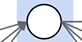

In [304]:
import random

class Neuron:

    def __init__(self, nin): # nin - number of inputs
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1,1))

    def __call__(self, x):
        # w * x + b
        zip(self.w, x) # zip functin peering up to a toupe the two elemnts: ((w1, x1),(w2, x2), ...)
        act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh() # Activation Function - getting us non-linearity and Squashing(-1 to 1)
        return out

    def parameters(self):
        return self.w + [self.b]

x = [2.0, 3.0]
n = Neuron(2) 
n(x) # seeing this sentex the compiler go to __call_ function 
''' the Neuron got random weights for every input, multiplly them with our inputs + b and then the activaton function'''

' the Neuron got random weights for every input, multiplly them with our inputs + b and then the activaton function'

now we want to create a Layer of neurons

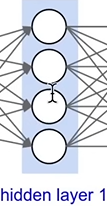

In [305]:
class Layer: # a list of Neurons

    def __init__(self, nin, nout): # nout - how many neurons we have in a single layer
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
        params = []
        for neuron in self.neurons:
            ps = neuron.parameters()
            params.extend(ps)
        return params
        # in one line: return [p for neuron in self.neurons for p in neuron.parameters()]

x = [2.0, 3.0]
n = Layer(2, 3)
n(x)

[Value(data=0.9546307725601049),
 Value(data=-0.9999305996881058),
 Value(data=0.9708326243840558)]

Now lets create an MLP

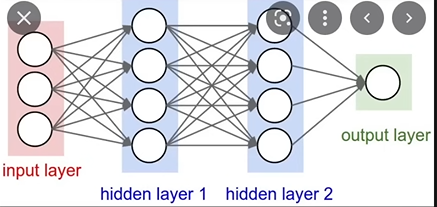

In [306]:
random.seed(42)

class MLP:
    def __init__(self, nin, nouts): # nouts - list of all the sizes of layers we want in our MLP
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

x = [2.0, 3.0, -1.0]
n = MLP(3, [4, 4, 1]) # just like the picture, hidden layer 1 is 4 neurons, hidden layer 2 is...
n(x)

Value(data=0.6994093620224068)

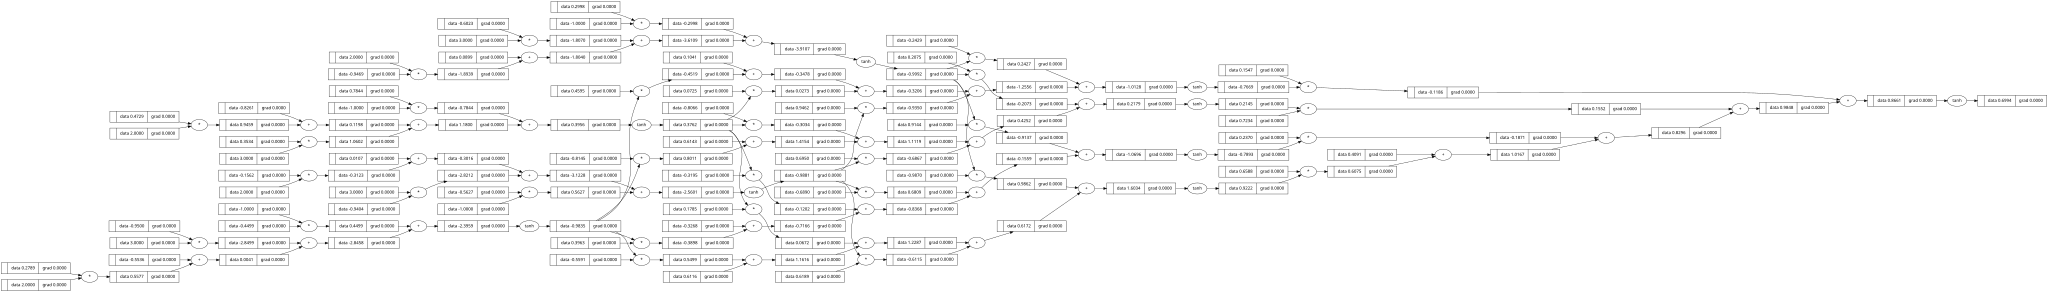

In [307]:
draw_dot(n(x))

In [308]:
# reseting the neural net:
x = [2.0, 3.0, -1.0]
n = MLP(3, [4, 4, 1]) # just like the picture, hidden layer 1 is 4 neurons, hidden layer 2 is...
n(x)

Value(data=-0.5846709101611409)

### creating a tiny dataset, writing the loss function


In [309]:
xs = [
    [2.0, 3.0, -1.0], 
    [3.0, -1.0, 0.5], 
    [0.5, 1.0, 1.0], 
    [1.0, 1.0, -1.0],
]

ys = [1.0, -1.0, -1.0, 1.0] # desired targets
ypreb = [n(x) for x in xs]
ypreb


[Value(data=-0.5846709101611409),
 Value(data=-0.604323823158572),
 Value(data=-0.5401311522071972),
 Value(data=-0.5642842053608851)]

from the output above we see the result for diffrent inputs:

for x = [2.0, 3.0, -1.0] we get 0.6994093620224068 -> we want this to be higher, going to 1

for x = [3.0, -1.0, 0.5] we get 0.5026295816615511 -> we want this to be lower, going to -1

etc

so how do TUNE the wieghts to better predect the desired targets ? the trick in deep learning to achive this is to calculate a single number that somehow measures the 
total performance of our NN. we call this single number THE LOSS (how well our NN is preforming)

In [310]:
# before optimizition our loss will be high, as we can see we want 1 and got 0.69 etc
[(yout - ygt)**2 for ygt, yout in zip(ys, ypreb)] # for example (1-0.6994093620224068)^2 = 0.0903...

[Value(data=2.5111818935109387),
 Value(data=0.15655963691984898),
 Value(data=0.21147935717028002),
 Value(data=2.4469850751415354)]

In [311]:
loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypreb)) # the sum of the values in the output above
loss

Value(data=5.326205962742604)

In [312]:
loss.backward()

In [313]:
# the gradient of the praticular wieght of praticular neuron of a praticular layer. this can be for every neuron
n.layers[0].neurons[0].w[0].grad # = -1.3 -> influance of this neuron on the loss is nagetive so increasing it will make the loss go down (יחס הפוך)

-0.012853460015882896

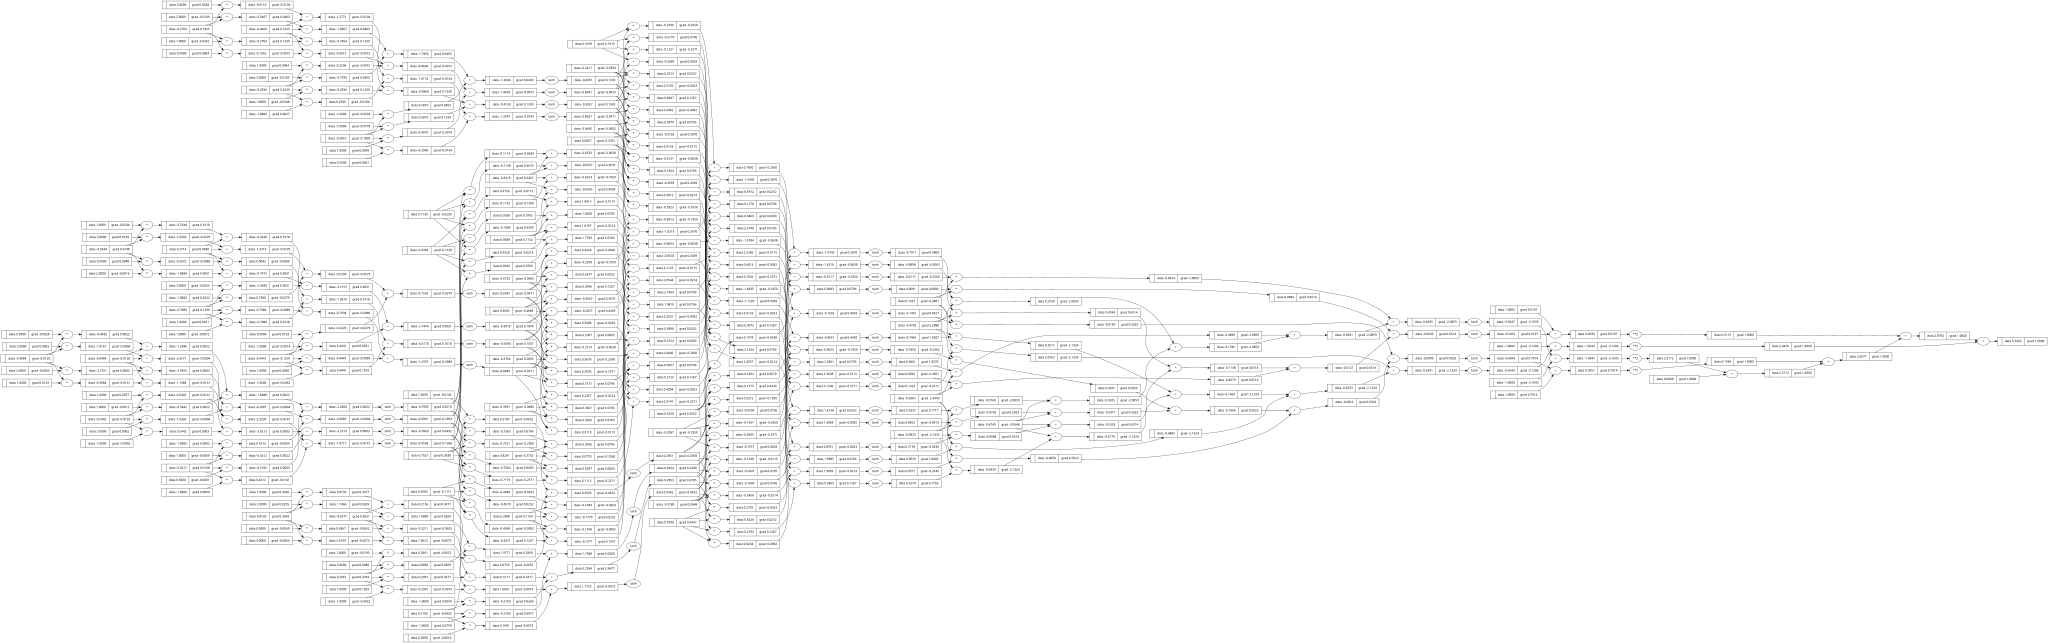

In [314]:
draw_dot(loss)

### collecting all of the parameters of the neural net

we will want to gather up all of the parameters of the NN so we can operate on all of them simutaneously and every onw of them we will nudge a tiny amount based on the gradient information

In [315]:
n.parameters() # all the biases and weights inside the entire NN

[Value(data=-0.9083512326886756),
 Value(data=-0.5442034486969063),
 Value(data=-0.42122407279578566),
 Value(data=-0.840416046152745),
 Value(data=-0.5344182272779396),
 Value(data=-0.7979971411805418),
 Value(data=-0.44405279377981577),
 Value(data=0.27136888852880037),
 Value(data=-0.2703356420598315),
 Value(data=-0.2596380657662347),
 Value(data=-0.5809859384570246),
 Value(data=-0.4660443559017733),
 Value(data=0.873309175424988),
 Value(data=0.2960707704931871),
 Value(data=0.21826201133397638),
 Value(data=-0.657722703603806),
 Value(data=0.45825359590069836),
 Value(data=-0.6731950124761432),
 Value(data=-0.24108911648470444),
 Value(data=0.9790467012731905),
 Value(data=0.2799995197081857),
 Value(data=0.11389948754929247),
 Value(data=0.3692285019797492),
 Value(data=0.6857038403796192),
 Value(data=0.5519998230924896),
 Value(data=-0.5419038560717913),
 Value(data=-0.9357995121919245),
 Value(data=-0.36909390388183616),
 Value(data=-0.46451824804859454),
 Value(data=-0.5780

In [316]:
len(n.parameters()) # in total the MLP has 41 parameters

41

we are able to change the parameters

In [317]:
for p in n.parameters():
    p.data += 0.01 * p.grad # step size n the direction of the gradient (increasing loss)

for example if we take this neuron:

In [318]:
n.layers[0].neurons[0].w[0].grad

-0.012853460015882896

In [319]:
n.layers[0].neurons[0].w[0].data

-0.9084797672888344

we can see it's value is 0.27 and its gard is negative. then by doing w[0].data = w[0].data + 0.01 * w[0]. grad we are slightly making it's value smaller. 

and if this neuron value goes down then we actually INCREASE the loss. that's becuase it's gradient (=slope) is negative which means that when we increase this neuron the loss is increasing.  

but we want to minimiz the loss and not increase it so: 

In [320]:
for p in n.parameters():
    p.data += -0.01 * p.grad # step size n the direction of the gradient (increasing loss). a bigger learning rate can be over stepping

In [321]:
n.layers[0].neurons[0].w[0].data # a little bit bigger then above

-0.9083512326886756

So there are three steps (that iterating):
1. forward pass - taking the inputs and pushing them into the NN from begginng to the end (loss calculated)
2. backward pass - evaluating all the gardients using CHAIN RULE
3. upadte - using the gradients we calculat all the new values of the wighets that will decrease the loss

In [322]:
# forward pass
ypreb = [n(x) for x in xs]
loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypreb)) # the sum of the values in the output above
loss

Value(data=5.326205962742604)

In [323]:
# backward passs
loss.backward()

In [324]:
# update
for p in n.parameters():
    p.data += -0.01 * p.grad

In [325]:
ypreb

[Value(data=-0.5846709101611409),
 Value(data=-0.604323823158572),
 Value(data=-0.5401311522071972),
 Value(data=-0.5642842053608851)]

In [326]:
n.parameters()

[Value(data=-0.9080941634883579),
 Value(data=-0.5439366143929875),
 Value(data=-0.42156104058005034),
 Value(data=-0.8401757742100417),
 Value(data=-0.5348149200595491),
 Value(data=-0.8005946358538963),
 Value(data=-0.4414998262881912),
 Value(data=0.2700079678412158),
 Value(data=-0.27398629984553696),
 Value(data=-0.26491609826871065),
 Value(data=-0.5773671004187287),
 Value(data=-0.4692911105564599),
 Value(data=0.8663701763469304),
 Value(data=0.28866318941681285),
 Value(data=0.22712874256103444),
 Value(data=-0.6637644139555077),
 Value(data=0.4604762564531291),
 Value(data=-0.6718655304958632),
 Value(data=-0.2403017192391282),
 Value(data=0.9781721487185169),
 Value(data=0.2776711438123596),
 Value(data=0.12635901492997803),
 Value(data=0.3789640973293786),
 Value(data=0.6923657828805898),
 Value(data=0.5448963614835894),
 Value(data=-0.5547463395022837),
 Value(data=-0.933581915573315),
 Value(data=-0.3673224385603731),
 Value(data=-0.46331459481885556),
 Value(data=-0.5793

In [327]:
for k in range(20):
    # forward pass
    ypreb = [n(x) for x in xs]
    loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypreb)) # the sum of the values in the output above

    # backward pass
    loss.backward()

    # update
    for p in n.parameters():
        p.data += -0.01 * p.grad

    print(k, loss.data)


0 4.734188860599774
1 4.122315692952203
2 4.135282032874079
3 4.738366543279337
4 5.269853756755042
5 5.4653336006381705
6 5.291508583017508
7 4.723624250238962
8 3.902423154923829
9 3.501701889637637
10 3.8586803669717216
11 4.27926304071905
12 4.224265303386981
13 3.4072730942533473
14 2.1280836141782924
15 1.9433757800467202
16 2.3851767153979413
17 2.6430144891287832
18 2.5263290754438485
19 1.7902123240575964


In [328]:
ypreb

[Value(data=0.910987844996651),
 Value(data=-0.856989342946346),
 Value(data=0.32364358869756593),
 Value(data=0.9009809998628178)]

But we have a problem: we did not reset the gradients to zero!

Why does it matter? Because after the first iteration, we calculate the loss, perform a backward pass (to compute gradients), and update the weights. In the next iteration, we do a new forward pass with the updated weights to calculate the new loss. Now, we want to perform another backward pass to find how we should change our weights based on the new loss.

However, PyTorch (and our custom autograd engine in Value calss) accumulates gradients by default (grad += new_grad) instead of overwriting them (grad = new_grad). This accumulation is mathematically necessary for the chain rule when a variable is used multiple times in the same forward pass. But across different training iterations, if we don't manually reset them to zero, the new gradients will just keep adding up on top of the history of all previous iterations. The weights will be pushed in completely wrong directions, and our model will fail to learn.

In [329]:
for k in range(20):
    # forward pass
    ypreb = [n(x) for x in xs]
    loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypreb)) # the sum of the values in the output above

    # backward pass
    for p in n.parameters():
        p.gard = 0.0
    loss.backward()

    # update
    for p in n.parameters():
        p.data += -0.01 * p.grad

    print(k, loss.data)


0 0.41950582936130026
1 0.04839702198896711
2 0.04486818596500154
3 0.0673464376127404
4 0.1024416343331952
5 0.14549902662805725
6 0.17602068921071645
7 0.16484806853831352
8 0.11369194392707124
9 0.060086793357797
10 0.02698100572187981
11 0.01129624513876605
12 0.00462800136897379
13 0.0018829796705058437
14 0.0007615475522364691
15 0.00030571484921197223
16 0.00012183499584072591
17 4.832195342599405e-05
18 1.9161644482434297e-05
19 7.645051586876584e-06


In [330]:
ypreb

[Value(data=0.997612732975117),
 Value(data=-0.9999966354661274),
 Value(data=-0.999998377374746),
 Value(data=0.9986050111879367)]

then why does before reseing the gradientclacluations work ? beacuase we made a simple and samle example

if a training set is a million examples then we take only a part of it - called a batch - and do the three steps. 